# Проект "Книжное приложение"

## Описание проекта

В этом проекте будут использованы данные о чтении и прослушивании контента в сервисе Яндекс Книги.

## Цели и задачи проекта

Цель проекта - проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

Задачи, поставленные в проекте:

- Проверить гипотезу статистическими тестами
- Составить аналитическую записку

## Описание данных

Таблица `yandex_knigi_data.csv` содержит данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания)

Содержит следующие поля:
- `city` — город пользователя;
- `puid` — идентификатор пользователя;
- `hours` — длительность чтения или прослушивания в часах.

## Содержимое проекта

- Загрузка данных и знакомство с ними
- Проверка гипотезы в Python
- Аналитическая записка

## Загрузка данных и знакомство с ними

Загрузим данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv` и познакомимся с ними.

In [1]:
# Импортируем библиотеки для анализа данных
import pandas as pd
import numpy as np

# Загружаем библиотеку для визуализации данных
import matplotlib.pyplot as plt

# Импортируем библиотеку для проверки гипотез
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [3]:
# Загружаем датафрейм
df_knigi = pd.read_csv('https://code.s3.yandex.net/datasets/yandex_knigi_data.csv')

In [4]:
# Выводим первые строки датафрейма
df_knigi.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


In [5]:
# Выводим информацию о датафрейме
df_knigi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB


## Предобработка данных и сравнение групп

In [6]:
# Удалим лишний столбец с индексами
df_knigi = df_knigi.drop(columns=['Unnamed: 0'])

In [7]:
# Проверка дубликатов в puid
duplicates = df_knigi['puid'].duplicated().sum()
print(f"Количество дубликатов puid: {duplicates}")

Количество дубликатов puid: 244


In [8]:
# Удаление дубликатов в puid
df_knigi = df_knigi.drop_duplicates(subset=['puid'], keep='first')

In [9]:
# Проверим наличие отрицательных/нулевых строк в столбце hours
(df_knigi['hours'] <= 0).sum()

np.int64(0)

In [10]:
# Сравнение групп по city: размер группы и среднее значение hours
city_stats = df_knigi.groupby('city').agg(
    count_users=('puid', 'size'),
    avg_hours=('hours', 'mean')
).reset_index()
print(city_stats)

              city  count_users  avg_hours
0           Москва         6234  10.881092
1  Санкт-Петербург         2306  11.264433


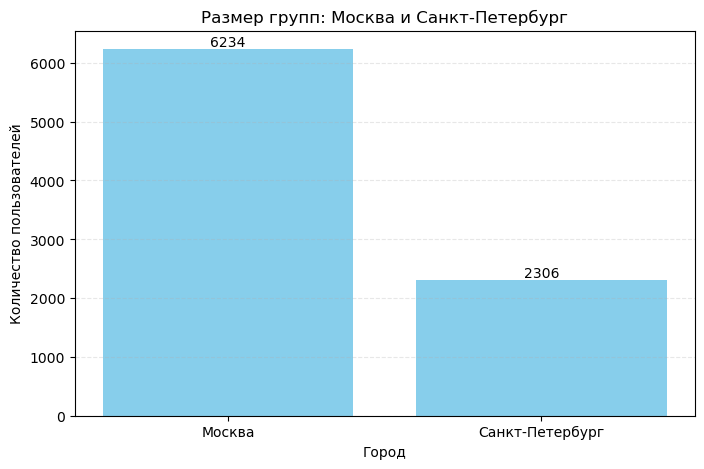

In [11]:
# Визуализация: столбчатая диаграмма для размеров групп
plt.figure(figsize=(8, 5))
plt.bar(city_stats['city'], city_stats['count_users'], color='skyblue')

# Добавление значений на столбцы
for i, val in enumerate(city_stats['count_users']):
    plt.text(i, val, f'{val}', ha='center', va='bottom')

plt.title('Размер групп: Москва и Санкт-Петербург')
plt.xlabel('Город')
plt.ylabel('Количество пользователей')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

Выводы:
- Из датафрейма был удален лишний столбец
- Было удалено 244 дубликата
- Количество пользователей в Москве более чем в 2,5 раза больше, чем в Санкт-Петербурге
- Средняя длительность чтения или прослушивания в часах среди пользователей на 3,52% выше Санкт-Петербург

## Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [12]:
# Проверяем независимость выборок
puid_msk = set(df_knigi.loc[df_knigi['city'] == 'Москва', 'puid'])
puid_spb = set(df_knigi.loc[df_knigi['city'] == 'Санкт-Петербург', 'puid'])
print('Пользователей в обоих городах:', len(puid_msk & puid_spb))

Пользователей в обоих городах: 0


In [13]:
# Готовим выборки
spb = df_knigi.loc[df_knigi['city'] == 'Санкт-Петербург', 'hours'].to_numpy()
msk = df_knigi.loc[df_knigi['city'] == 'Москва', 'hours'].to_numpy()

Для выборочного среднего подойдет Т-Тест Уэлча. Дополнительно проведем тест Манна-Уитни, на случай, если распределение окажется не достаточно нормальным.

In [14]:
alpha = 0.05

# Проводим T-тест Уэлча
t_stat, p_ttest = stats.ttest_ind(spb, msk, equal_var=False, alternative='greater')

print('=== t-тест Уэлча (односторонний) ===')
print(f'p-value = {p_ttest:.4f}')

=== t-тест Уэлча (односторонний) ===
p-value = 0.3436


In [15]:
# Дополнительно проведем тест Манна—Уитни
u_stat, p_mw = stats.mannwhitneyu(spb, msk, alternative='greater')

print('=== Манн—Уитни (односторонний) ===')
print(f'p-value = {p_mw:.4f}')

=== Манн—Уитни (односторонний) ===
p-value = 0.6190


In [16]:
# Функция для итога
def verdict(p):
    return 'H0 отвергается, различие между группами статистически значимо.' if p < alpha else 'H0 не отвергается, статистически значимого различия между группами не обнаружено'

In [17]:
# Результаты тестов
print(f'Уэлч:        p = {p_ttest:.4f} -> {verdict(p_ttest)}')
print(f'Манн—Уитни:  p = {p_mw:.4f} -> {verdict(p_mw)}')

Уэлч:        p = 0.3436 -> H0 не отвергается, статистически значимого различия между группами не обнаружено
Манн—Уитни:  p = 0.6190 -> H0 не отвергается, статистически значимого различия между группами не обнаружено


## Аналитическая записка

Итоги теста:
- Основным тестом был выбран Т-тест Уэлча, дополнительным - тест Манна-Уитни
- Уровень статистической значимости установлен на уровне 0.05
- Результат теста по Уэлчу: p = 0.3436, по Манну—Уитни: p = 0.6190
- Оба результата не дают оснований отвергнуть нулевую гипотезу. Следовательно, статистически значимого различия в средней активности между Москвой и Санкт-Петербургом не выявлено. Гипотеза о большей активности петербуржцев не подтверждена.
- Возможные причины полученных результатов:
    1. Реального различия между городами, скорее всего, нет или оно пренебрежимо мало.
    2. Выборка может быть недостаточной для обнаружения небольшого эффекта.